# Pivot trees on different data types

A pivot tree splits on the distance from *pivots*, instances of the training set: a rule such as `P_12 <= 3.5` sends left the instances closer than 3.5 to the training instance 12. The rules can therefore be read by looking at the pivots themselves, whatever the data are.

The pivot stumps work on vectors. As in the PivotTree paper, any data type is first mapped to a vector: tabular data as they are, images and time series by flattening their values, texts through an embedding. The distances are computed on the standardized vectors (categorical features one-hot encoded).

Here the same tree, of depth 2, is trained on tabular data, images, time series and texts, and its pivots are drawn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

from RuleTree import RuleTreeClassifier
from RuleTree.stumps.classification import MultiplePivotTreeStumpClassifier, PivotTreeStumpClassifier


def pivot_tree(X_train, y_train, stump=None):
    """A pivot tree of depth 2."""
    stump = PivotTreeStumpClassifier() if stump is None else stump
    return RuleTreeClassifier(max_depth=2, random_state=0, base_stumps=stump).fit(X_train, y_train)


def split_pivots(model):
    """Node id -> pivots of its split (indices of the training set)."""
    pivots = {}
    for node_id, node in model.get_predicates().items():
        used = node.stump.get_pivots()["used"]
        pivots[node_id] = used if isinstance(used, list) else [used]
    return pivots

## Tabular data

The iris flowers: four measures of each flower. The pivots are flowers of the training set, drawn with larger markers on two of the measures.

In [2]:
from sklearn.datasets import load_iris

iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.3, stratify=iris.target,
                                                    random_state=0)

model = pivot_tree(X_train, y_train)
print("accuracy:", round(accuracy_score(y_test, model.predict(X_test)), 3))
model.print_rules(model.get_rules())

accuracy: 0.844
|--- P_54 <= 2.985
|   |--- P_50 <= 1.332
|   |    output: 1
|   |--- P_50 > 1.332
|   |    output: 2
|--- P_54 > 2.985
|    output: 0


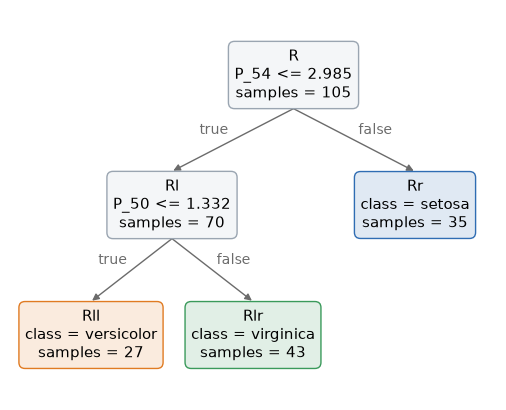

In [3]:
model.plot_tree(class_names=list(iris.target_names))
plt.show()

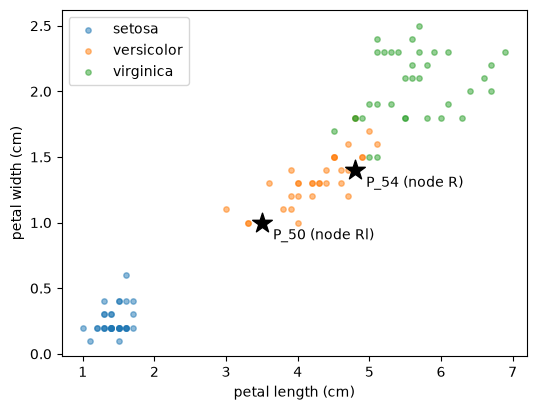

In [4]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for label, name in enumerate(iris.target_names):
    ax.scatter(*X_train[y_train == label][:, 2:].T, s=15, alpha=0.5, label=name)
for node_id, (pivot,) in split_pivots(model).items():
    ax.scatter(*X_train[pivot, 2:], s=220, marker="*", color="black")
    ax.annotate(f"P_{pivot} (node {node_id})", X_train[pivot, 2:], xytext=(8, -12), textcoords="offset points")
ax.set_xlabel(iris.feature_names[2])
ax.set_ylabel(iris.feature_names[3])
ax.legend()
plt.show()

## Images

The handwritten digits of scikit-learn: images of 8 x 8 pixels, flattened into 64 values. A tree of depth 2 has at most four leaves, so the example keeps four digits. A pivot is an image, so a rule reads as "closer than *t* to this digit".

accuracy: 0.718


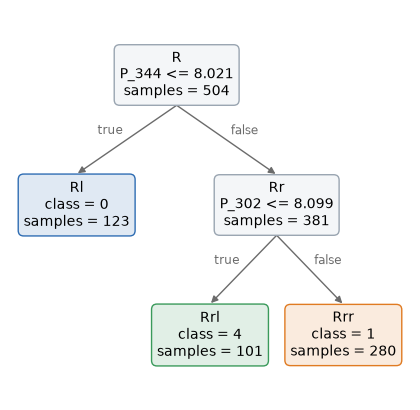

In [5]:
from sklearn.datasets import load_digits

digits = load_digits()
four = np.isin(digits.target, [0, 1, 4, 7])
X_img = digits.images[four].reshape(four.sum(), -1)
X_train, X_test, y_train, y_test = train_test_split(X_img, digits.target[four], test_size=0.3,
                                                    stratify=digits.target[four], random_state=0)

model = pivot_tree(X_train, y_train)
print("accuracy:", round(accuracy_score(y_test, model.predict(X_test)), 3))
model.plot_tree()
plt.show()

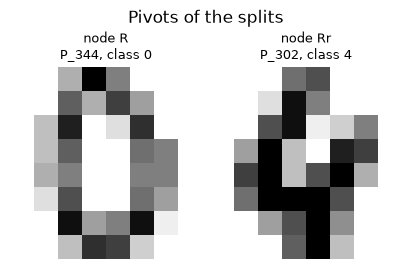

In [6]:
def show_images(pivots, labels, shape, title):
    fig, axes = plt.subplots(1, len(pivots), figsize=(2 * len(pivots), 2.8), squeeze=False, layout="constrained")
    for ax, (caption, pivot) in zip(axes[0], pivots):
        ax.imshow(X_train[pivot].reshape(shape), cmap="gray_r")
        ax.set_title(f"{caption}\nP_{pivot}, class {labels[pivot]}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


show_images([(f"node {node_id}", pivot) for node_id, (pivot,) in split_pivots(model).items()], y_train, (8, 8),
            "Pivots of the splits")

With `MultiplePivotTreeStumpClassifier` (the proximity variant of the paper), each split compares two pivots: `P_a <= P_b` sends left the images closer to `a` than to `b`.

accuracy: 0.727
|--- P_80 <= P_348
|   |--- P_67 <= P_80
|   |    output: 0
|   |--- P_67 > P_80
|   |    output: 4
|--- P_80 > P_348
|   |--- P_201 <= P_352
|   |    output: 1
|   |--- P_201 > P_352
|   |    output: 7


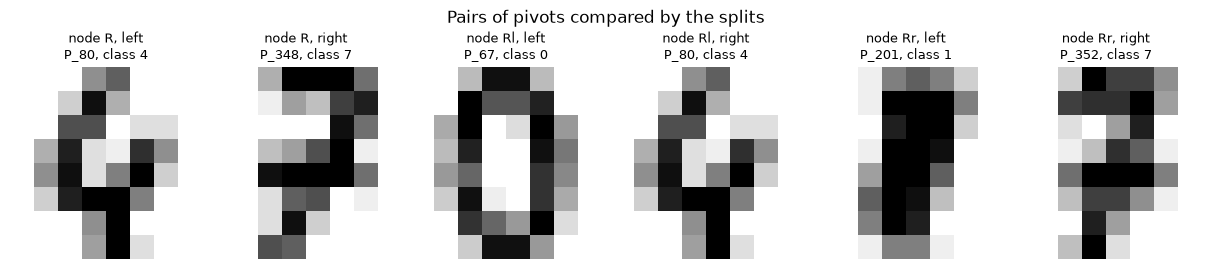

In [7]:
proximity_model = pivot_tree(X_train, y_train, MultiplePivotTreeStumpClassifier())
print("accuracy:", round(accuracy_score(y_test, proximity_model.predict(X_test)), 3))
proximity_model.print_rules(proximity_model.get_rules())

pairs = [(f"node {node_id}, {side}", pivot) for node_id, pivots in split_pivots(proximity_model).items()
         for side, pivot in zip(("left", "right"), pivots)]
show_images(pairs, y_train, (8, 8), "Pairs of pivots compared by the splits")

## Time series

The Cylinder-Bell-Funnel data set (Saito, 1994), a classic synthetic benchmark of time series classification: each series is noise plus a plateau (cylinder), an increasing ramp (bell) or a decreasing ramp (funnel), starting and ending at random times. The series of 128 values are used as vectors, and a pivot is a whole series: below, the pivot of each split (thick line) over a few training series of each class.

accuracy: 0.844


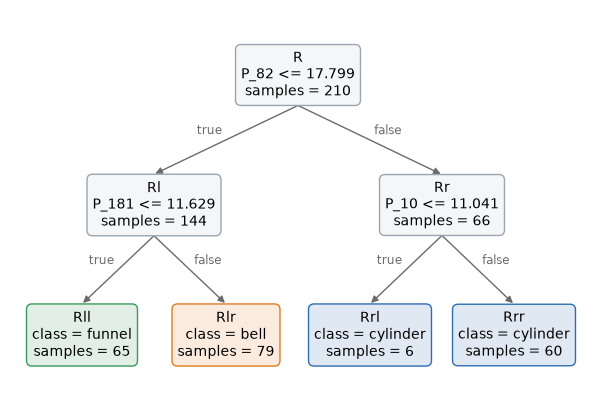

In [8]:
def cylinder_bell_funnel(n_per_class, length=128, seed=0):
    """The Cylinder-Bell-Funnel time series (Saito, 1994)."""
    rng = np.random.default_rng(seed)
    t = np.arange(length)
    series, labels = [], []
    for label in range(3):
        for _ in range(n_per_class):
            a = rng.integers(16, 32)
            b = a + rng.integers(32, 96)
            inside = (t >= a) & (t <= b)
            shape = inside * [1.0, (t - a) / (b - a), (b - t) / (b - a)][label]
            series.append((6 + rng.normal()) * shape + rng.normal(size=length))
            labels.append(label)
    return np.array(series), np.array(labels)


cbf_names = ["cylinder", "bell", "funnel"]
X_ts, y_ts = cylinder_bell_funnel(100)
X_train, X_test, y_train, y_test = train_test_split(X_ts, y_ts, test_size=0.3, stratify=y_ts, random_state=0)

model = pivot_tree(X_train, y_train)
print("accuracy:", round(accuracy_score(y_test, model.predict(X_test)), 3))
model.plot_tree(class_names=cbf_names)
plt.show()

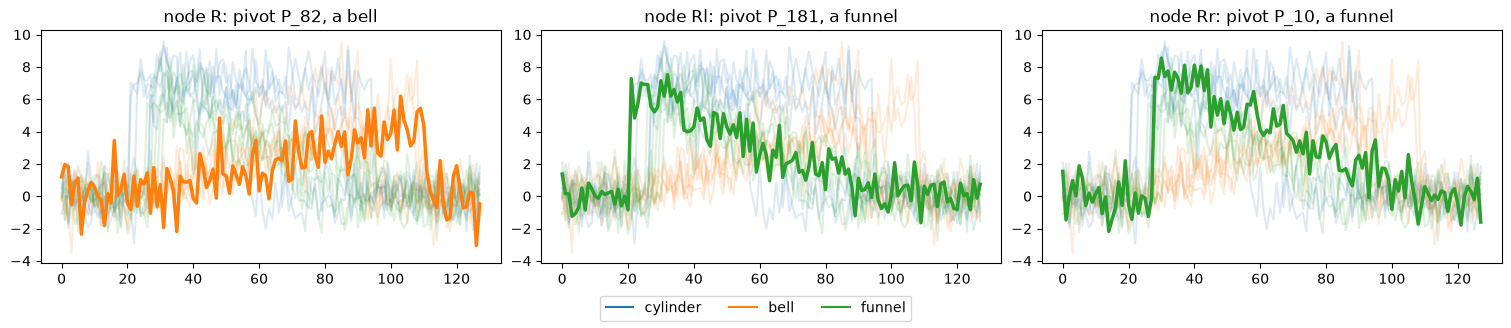

In [9]:
pivots = split_pivots(model)
fig, axes = plt.subplots(1, len(pivots), figsize=(5 * len(pivots), 3.2), squeeze=False, layout="constrained")
for ax, (node_id, (pivot,)) in zip(axes[0], pivots.items()):
    for label, name in enumerate(cbf_names):  # a few series of each class, in the background
        for series in X_train[y_train == label][:5]:
            ax.plot(series, color=f"C{label}", alpha=0.15)
    ax.plot(X_train[pivot], color=f"C{y_train[pivot]}", linewidth=2.5)
    ax.set_title(f"node {node_id}: pivot P_{pivot}, a {cbf_names[y_train[pivot]]}")
handles = [plt.Line2D([], [], color=f"C{label}", label=name) for label, name in enumerate(cbf_names)]
fig.legend(handles=handles, loc="outside lower center", ncols=3)
plt.show()

## Texts

The paper embeds the texts with a sentence transformer. To keep this example self-contained, the embedding here is TF-IDF followed by a truncated SVD (latent semantic analysis), normalized to unit length, on a small corpus of sentences about two topics. The pivots are sentences of the training set.

In [10]:
rng = np.random.default_rng(0)
topics = {
    "sport": (["The striker", "Our goalkeeper", "The coach", "The home team", "That runner", "The referee"],
              ["scored a late goal", "won the final match", "trained on the pitch", "lost the derby",
               "broke the record at the stadium", "celebrated the championship"]),
    "cooking": (["My grandmother", "The chef", "This recipe", "The bakery", "Our cook", "That pastry"],
                ["baked fresh bread", "needs garlic and olive oil", "simmered the tomato sauce",
                 "served a warm soup", "uses butter and flour", "roasted vegetables in the oven"]),
}
texts, text_labels = [], []
for topic, (subjects, predicates) in topics.items():
    for _ in range(60):
        texts.append(f"{rng.choice(subjects)} {rng.choice(predicates)}.")
        text_labels.append(topic)
texts, text_labels = np.array(texts), np.array(text_labels)
texts_train, texts_test, y_train, y_test = train_test_split(texts, text_labels, test_size=0.3,
                                                            stratify=text_labels, random_state=0)

In [11]:
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

embedding = make_pipeline(TfidfVectorizer(), TruncatedSVD(n_components=10, random_state=0), Normalizer())
X_train = embedding.fit_transform(texts_train)
X_test = embedding.transform(texts_test)

model = pivot_tree(X_train, y_train)
print("accuracy:", round(accuracy_score(y_test, model.predict(X_test)), 3))
for node_id, (pivot,) in split_pivots(model).items():
    print(f"node {node_id}: P_{pivot} = {str(texts_train[pivot])!r} ({y_train[pivot]})")

accuracy: 0.917
node R: P_15 = 'The referee scored a late goal.' (sport)
node Rr: P_11 = 'That runner celebrated the championship.' (sport)


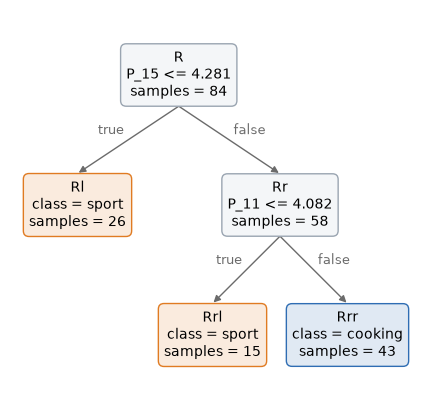

In [12]:
model.plot_tree()
plt.show()

## Reading a prediction

The path of an instance is a sequence of comparisons with the pivots: here, for a sentence of the test set, its distance from the pivot of each node it crosses.

In [13]:
sentence = str(texts_test[0])
x = X_test[:1]
node = model.root
print(repr(sentence))
while not node.is_leaf():
    (pivot,) = split_pivots(model)[node.node_id]
    distance = node.stump.transformer_.transform(x)[0, 0]
    goes_left = model.apply(x)[0].startswith(node.node_id + "l")
    print(f"  node {node.node_id}: distance {distance:.3f} from {str(texts_train[pivot])!r} -> {'left' if goes_left else 'right'}")
    node = node.node_l if goes_left else node.node_r
print("prediction:", model.predict(x)[0])

'The bakery served a warm soup.'
  node R: distance 4.829 from 'The referee scored a late goal.' -> right
  node Rr: distance 4.867 from 'That runner celebrated the championship.' -> right
prediction: cooking
